# EDA 01: chất lượng và quy mô dữ liệu

Dữ liệu thô có gì, lỗi ở đâu và bao nhiêu, mỗi user có bao nhiêu dữ liệu. Notebook chỉ mô tả, không đặt ngưỡng.

| Mục | Câu hỏi | Làm căn cứ cho |
|---|---|---|
| 1 | Dữ liệu có gì, chất lượng ra sao (trùng, lỗi tọa độ, lỗi thời gian)? | Mô tả lỗi dữ liệu và dòng trùng |
| 2 | Mỗi user có bao nhiêu dữ liệu, chênh lệch thế nào? | Mô tả quy mô dữ liệu theo user |
| 3 | Lỗi thời gian; dòng trùng timestamp: bao nhiêu, trùng ở cột nào, hai kiểu trùng (3.1–3.3); file trùng giữa các user (3.4) | Mô tả; nhóm user trùng file để chia (D17) |

**Cách chạy.** Cần chạy một lần `python src/preprocess/convert_raw.py` trước (chuyển dữ liệu thô sang `data/interim`). Sau đó Run All; notebook nạp dữ liệu từ `data/interim` và tính trong khoảng 1–2 phút. Muốn chạy thử nhanh thì đặt `USERS_LIMIT` ở cell đầu. Trong cùng một phiên, chỉ sửa cell phân tích thì chỉ cần chạy lại cell đó.

**Mục 3.1–3.3 và 3.4 đọc lại file `.plt` gốc** (cần `data/raw/geolife`), vì `data/interim` đã bỏ độ cao và cột ngày. Lần đầu quét mọi user mất khoảng 10 phút; kết quả lưu ở `data/interim/dup_scan/`, các lần sau chỉ đọc lại.

**Không có ở đây:** chọn quy tắc xử lý dòng trùng và ngưỡng lệch (mục 1 của notebook 05) vì đó là chọn ngưỡng: xem `notebooks/tuning/05_duplicate_rules.ipynb`.

Code tính toán nằm trong `src/eda/` (`scan.py`, `config.py`; riêng mục 3 là `duplicates.py`). Mục đánh số riêng trong từng notebook (bảng mục và notebook ở README).

**Quy ước.** Timestamp gốc là UTC (theo User Guide). "Giờ địa phương" theo giả thuyết ở `src/eda/config.py`, kiểm chứng ở notebook 03 mục 2. Một "bước" là cặp hai điểm liên tiếp của cùng user sau khi sắp xếp theo thời gian và bỏ timestamp trùng.

> **Giai đoạn: KHẢO SÁT (trước khi chia validation / test).** Chạy trên **toàn bộ 182 user**. Chỉ mô tả dữ liệu, **không chọn ngưỡng** ở đây. Ngưỡng chọn ở thư mục `notebooks/tuning/`, chỉ trên nhóm validation (D17).
>
> Các số trong ô văn bản bên dưới là của lần chạy cũ (bản chia 06/11); cập nhật sau khi chạy lại.

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT / "src"))
from eda.config import *          # dữ kiện từ tài liệu, mốc mô tả, bins (xem src/eda/config.py)
from eda.utils import pct, hist_quantile, qtable, fmt_s
from eda.scan import run
from eda import split

USERS_LIMIT = None   # khảo sát: toàn bộ user (chỉ mô tả, không chọn ngưỡng)

pd.set_option("display.max_columns", 30)
plt.rcParams["figure.dpi"] = 100

R = run(topics=[], users=USERS_LIMIT)
users, files, A = R.users, R.files, R.A

print(f"{len(users)} user, {len(files):,} file")

[20/182] đã đọc tới user 019 (3 giây)


[40/182] đã đọc tới user 039 (6 giây)


[60/182] đã đọc tới user 059 (8 giây)


[80/182] đã đọc tới user 079 (9 giây)


[100/182] đã đọc tới user 099 (10 giây)


[120/182] đã đọc tới user 119 (11 giây)


[140/182] đã đọc tới user 139 (12 giây)


[160/182] đã đọc tới user 159 (14 giây)


[180/182] đã đọc tới user 179 (16 giây)
[182/182] đã đọc tới user 181 (16 giây)
182 user, 18,670 file


## 1. Tổng quan và chất lượng dữ liệu

**Câu hỏi:** dữ liệu có bao nhiêu, và bao nhiêu phần trăm có vấn đề?

- `n_raw`: số dòng đọc được từ file.
- `n_bad_coord`: tọa độ ngoài phạm vi hợp lệ.
- `n_nat`: timestamp không đọc được.
- `n_dup`: timestamp trùng trong cùng user (giữ bản đầu).
- `n_bad_time`: timestamp ngoài 04/2007–08/2012 (khoảng thu thập theo User Guide).

In [2]:
n_raw = users["n_raw"].sum()
print(f"User: {len(users)}  |  File: {len(files):,}  |  User có nhãn phương tiện: {int(users['has_labels'].sum())}")
print(f"Điểm thô: {n_raw:,}  |  Sau khi bỏ trùng: {users['n_points'].sum():,}  |  Bước: {int(A['n_steps']):,}")
print(f"Thời gian (thô): {users['start'].min()} đến {users['end'].max()}")
print(f"Thời gian (hợp lệ): {users['start_valid'].min()} đến {users['end_valid'].max()}")

quality = pd.DataFrame({"số_điểm": users[["n_bad_coord", "n_nat", "n_dup", "n_bad_time"]].sum()})
quality["tỷ_lệ_%"] = quality["số_điểm"] / n_raw * 100
quality["số_user_bị"] = (users[["n_bad_coord", "n_nat", "n_dup", "n_bad_time"]] > 0).sum()
quality.round(4)

User: 182  |  File: 18,670  |  User có nhãn phương tiện: 69
Điểm thô: 24,876,978  |  Sau khi bỏ trùng: 24,178,078  |  Bước: 24,177,896
Thời gian (thô): 2000-01-01 23:12:19+00:00 đến 2012-07-27 08:31:20+00:00
Thời gian (hợp lệ): 2007-04-12 09:31:32+00:00 đến 2012-07-27 08:31:20+00:00


,số_điểm,tỷ_lệ_%,số_user_bị
n_bad_coord,1,0.0000,1
n_nat,0,0.0000,0
n_dup,698900,2.8094,74
n_bad_time,3,0.0000,1


### 1.1 File

Mỗi file `.plt` thường là một lần bật ghi. Thời lượng file cho biết user ghi liên tục cả ngày hay chỉ ghi từng chuyến đi.

,n_points,duration_min
count,18670.0,18670.0
mean,1332.5,161.3
std,2821.5,260.0
min,3.0,0.0
10%,66.0,7.5
50%,506.0,42.1
90%,3323.1,530.4
99%,11624.6,1039.5
max,92645.0,5807.2


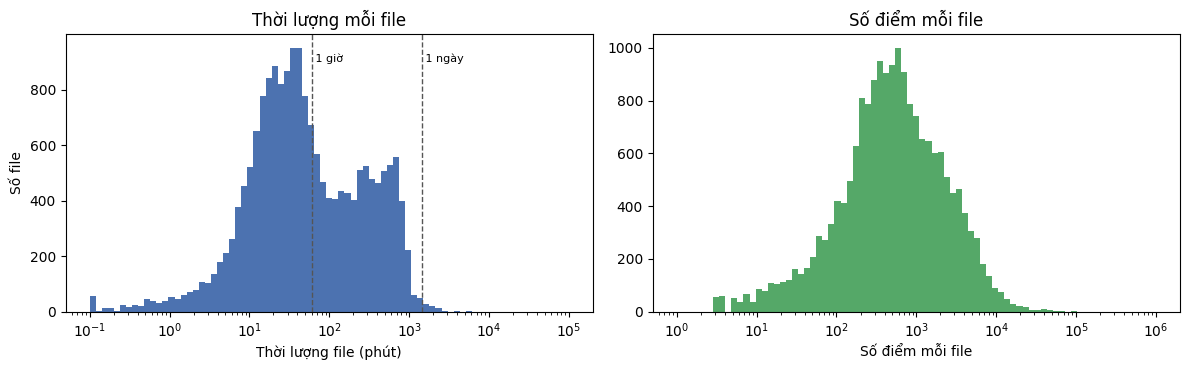

File dài hơn 12 giờ: 917 / 18,670


In [3]:
display(files[["n_points", "duration_min"]].describe(percentiles=[0.1, 0.5, 0.9, 0.99]).round(1))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
d = files["duration_min"].clip(lower=0.1)
axes[0].hist(d, bins=np.logspace(-1, 5, 80), color="#4c72b0")
axes[0].set_xscale("log")
for x, lab in ((60, "1 giờ"), (1440, "1 ngày")):
    axes[0].axvline(x, color="#555", ls="--", lw=1)
    axes[0].text(x, axes[0].get_ylim()[1] * 0.9, f" {lab}", fontsize=8)
axes[0].set_xlabel("Thời lượng file (phút)")
axes[0].set_ylabel("Số file")
axes[0].set_title("Thời lượng mỗi file")
axes[1].hist(files["n_points"].clip(lower=1), bins=np.logspace(0, 6, 80), color="#55a868")
axes[1].set_xscale("log")
axes[1].set_xlabel("Số điểm mỗi file")
axes[1].set_title("Số điểm mỗi file")
plt.tight_layout()
plt.show()
print(f"File dài hơn 12 giờ: {(files['duration_min'] > 720).sum()} / {len(files):,}")

## 2. Quy mô dữ liệu theo user

**Câu hỏi:** mỗi user có bao nhiêu dữ liệu, có chênh lệch lớn không, và user nào quá ít để suy ra home/office?

- `n_days`: số ngày (giờ địa phương) có ít nhất một điểm.
- `span_days`: từ điểm hợp lệ đầu tiên đến cuối cùng, tính bằng ngày (có phần lẻ).
- `n_span_days`: số ngày địa phương từ ngày đầu đến ngày cuối, tính cả hai đầu.
- `active_ratio`: `n_days / n_span_days`, luôn trong (0, 1]. Hai đại lượng cùng đếm theo ngày địa phương; nếu chia cho `span_days` (tính theo UTC) thì user ghi vắt qua nửa đêm sẽ có tỷ lệ > 1. Gần 1 là ghi gần như mỗi ngày, gần 0 là ghi rải rác.

In [4]:
users[["n_files", "n_points", "n_days", "span_days", "active_ratio", "data_hours"]].describe(
    percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).round(2)


,n_files,n_points,n_days,span_days,active_ratio,data_hours
count,182.00,182.00,182.00,182.00,182.00,182.00
mean,102.58,132846.58,61.29,173.41,0.55,117.87
std,250.06,264333.78,131.62,318.54,0.30,226.61
min,1.00,17.00,1.00,0.00,0.01,0.13
10%,3.10,718.90,4.00,3.21,0.13,4.12
25%,8.00,3359.00,7.00,9.97,0.30,10.82
50%,27.50,35181.50,21.50,70.30,0.52,33.32
75%,89.75,122957.00,63.00,166.66,0.80,113.75
90%,214.70,386695.30,133.30,362.89,1.00,366.59
max,2153.00,2156964.00,1252.00,1932.92,1.00,1639.05


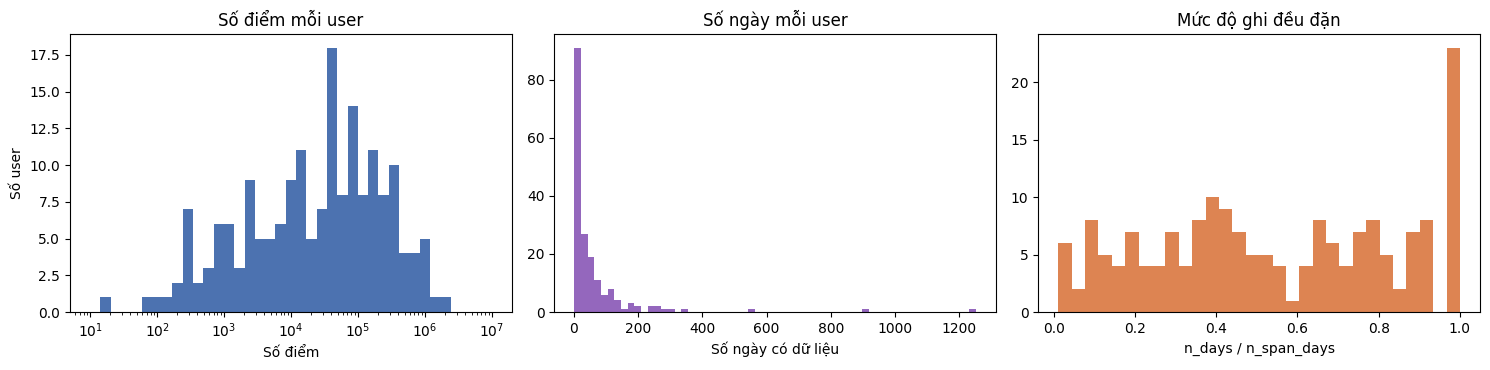

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].hist(users["n_points"].clip(lower=1), bins=np.logspace(1, 7, 40), color="#4c72b0")
axes[0].set_xscale("log"); axes[0].set_xlabel("Số điểm"); axes[0].set_ylabel("Số user")
axes[0].set_title("Số điểm mỗi user")
axes[1].hist(users["n_days"], bins=60, color="#9467bd")
axes[1].set_xlabel("Số ngày có dữ liệu"); axes[1].set_title("Số ngày mỗi user")
axes[2].hist(users["active_ratio"], bins=30, color="#dd8452")
axes[2].set_xlabel("n_days / n_span_days"); axes[2].set_title("Mức độ ghi đều đặn")
plt.tight_layout()
plt.show()

**Độ tập trung:** nếu vài user chiếm phần lớn dữ liệu, các thống kê gộp (phân vị tốc độ, heatmap) chủ yếu phản ánh những user đó.

In [6]:
s = users["n_points"].sort_values(ascending=False).to_numpy()
cum = np.cumsum(s) / s.sum() * 100
for k in [x for x in (1, 5, 10, 20, 50) if x <= len(s)]:
    print(f"Top {k:>2} user chiếm {cum[k - 1]:5.1f}% số điểm")
users.nlargest(10, "n_points")[["user", "n_points", "n_days", "span_days", "share_bj"]]

Top  1 user chiếm   8.9% số điểm
Top  5 user chiếm  26.5% số điểm
Top 10 user chiếm  41.9% số điểm
Top 20 user chiếm  60.7% số điểm
Top 50 user chiếm  86.3% số điểm


,user,n_points,n_days,span_days,share_bj
153,153,2156964,1252,1793.488854,0.725852
128,128,1208309,911,1426.294375,0.798467
41,041,1057038,138,149.199803,0.981379
17,017,1026176,195,247.111620,0.997561
163,163,969084,559,1932.923657,0.550159
68,068,937876,295,363.991748,0.955787
10,010,931815,124,595.086354,0.275348
25,025,629891,189,208.385139,0.635515
30,030,615940,184,196.963715,0.962081
167,167,608657,255,352.960486,0.853246


**User ít dữ liệu:** số user dưới mỗi mức số ngày (các mức chỉ là mốc mô tả). Đây là căn cứ để chọn ngưỡng dữ liệu tối thiểu ở bước gán home/office.


In [7]:
display(pd.DataFrame({f"n_days < {k}": [(users["n_days"] < k).sum()] for k in (2, 3, 7, 14, 30)}, index=["số user"]))
users.nsmallest(10, "n_points")[["user", "n_points", "n_days", "data_hours", "start_valid", "end_valid"]]


,n_days < 2,n_days < 3,n_days < 7,n_days < 14,n_days < 30
số user,2,12,42,69,108


,user,n_points,n_days,data_hours,start_valid,end_valid
60,060,17,2,0.233333,2007-08-18 04:26:05+00:00,2007-08-20 01:59:13+00:00
72,072,81,2,1.166667,2007-07-20 06:49:48+00:00,2007-07-21 03:52:23+00:00
178,178,84,1,0.133333,2010-03-12 17:26:08+00:00,2010-03-12 17:33:08+00:00
87,087,152,6,1.366667,2007-08-15 00:37:06+00:00,2007-08-20 00:54:01+00:00
171,171,177,5,2.616667,2007-07-23 03:31:53+00:00,2007-07-28 11:11:18+00:00
107,107,199,3,2.900000,2007-10-02 07:33:29+00:00,2007-10-07 01:28:16+00:00
146,146,272,8,3.466667,2007-07-31 13:50:53+00:00,2007-08-09 01:50:08+00:00
164,164,286,7,4.050000,2007-11-30 07:55:08+00:00,2007-12-09 13:28:15+00:00
175,175,308,4,4.433333,2007-10-19 05:23:15+00:00,2007-10-22 01:56:45+00:00
90,090,320,6,4.116667,2007-07-22 00:03:41+00:00,2007-07-29 05:05:46+00:00


## 3. Lỗi thời gian và dòng trùng

**Câu hỏi:** điểm có timestamp ngoài 04/2007–08/2012 nằm ở đâu? Dòng trùng timestamp chiếm bao nhiêu, trùng ở cột nào? Notebook này chỉ mô tả.

| Mục | Nội dung |
|---|---|
| 3.1 | Tỷ lệ dòng trùng timestamp |
| 3.2 | Dòng trùng giống nhau ở cột nào: trùng hoàn toàn hay một phần |
| 3.3 | Hai kiểu trùng theo cỡ nhóm |
| 3.4 | File trùng giữa các user |

Chọn quy tắc xử lý dòng trùng: mục 1 của `notebooks/tuning/05_duplicate_rules.ipynb`.


In [8]:
bad = users[users["n_bad_time"] > 0][["user", "n_points", "n_bad_time", "start", "end"]]
display(bad)
bad_files = files[(files["start"] < TIME_MIN) | (files["end"] >= TIME_MAX)]
print(f"File có điểm ngoài 04/2007–08/2012: {len(bad_files)}")
bad_files

,user,n_points,n_bad_time,start,end
163,163,969084,3,2000-01-01 23:12:19+00:00,2012-07-27 08:31:20+00:00


File có điểm ngoài 04/2007–08/2012: 1


,user,file,n_points,start,end,duration_min
17090,163,20000101231219.plt,3,2000-01-01 23:12:19+00:00,2000-01-01 23:15:23+00:00,3.066667


### 3.1 Tỷ lệ dòng trùng timestamp

Đọc lại file `.plt` gốc của mọi user, đủ 7 trường (lat, lon, cột 0, độ cao, cột ngày, date, time).

- **Nhóm trùng:** các dòng của cùng một user có cùng timestamp.
- **Dòng thừa:** số dòng của nhóm trừ 1, tức số dòng bị bỏ nếu chỉ giữ một dòng mỗi timestamp.
- **Dòng đầu nhóm:** dòng xuất hiện trước tiên trong file, là dòng pipeline đang giữ (A3). Mọi so sánh bên dưới là **so dòng thừa với dòng đầu nhóm**.

In [9]:
import importlib
from eda import duplicates as dups
importlib.reload(dups)   # nạp lại code mới nếu kernel đã import bản cũ

REBUILD_DUP_SCAN = False   # True để đọc lại toàn bộ file .plt gốc (khoảng 10 phút)
# Cache cho toàn bộ user (dup_scan); đổi USERS_LIMIT thì xoá thư mục đó
PU, EX = dups.scan_all_users(users=USERS_LIMIT, cache_dir=ROOT / "data" / "interim" / "dup_scan",
                             rebuild=REBUILD_DUP_SCAN)
EX["user"] = EX["user"].astype(str)
n_all, n_extra = int(PU["n_rows"].sum()), len(EX)

ov = pd.DataFrame({"số dòng": {
    "tổng dòng thô": n_all,
    "dòng thuộc nhóm trùng": int(PU["n_in_groups"].sum()),
    "số nhóm trùng (timestamp bị trùng)": int(PU["n_groups"].sum()),
    "dòng thừa": n_extra,
}})
ov["% tổng dòng thô"] = (ov["số dòng"] / n_all * 100).round(2)
print(f"User có dòng trùng: {(PU['n_extra'] > 0).sum()} / {len(PU)}")
ov

User có dòng trùng: 74 / 182


,số dòng,% tổng dòng thô
tổng dòng thô,24876978,100.00
dòng thuộc nhóm trùng,911309,3.66
số nhóm trùng (timestamp bị trùng),212409,0.85
dòng thừa,698900,2.81


,dòng thừa,dòng thừa % (của user),trùng hoàn toàn %,cỡ nhóm,% tổng dòng thừa (cộng dồn)
user,,,,,
065,307173,72.1,10.0,5,44.0
141,249361,79.4,10.4,5,79.6
165,68281,52.2,29.2,5,89.4
179,14084,8.3,100.0,2,91.4
058,11000,44.4,3.9,5,93.0
059,11000,46.6,3.9,5,94.6
167,9992,1.6,99.9,2,96.0
126,9846,2.3,100.0,2,97.4


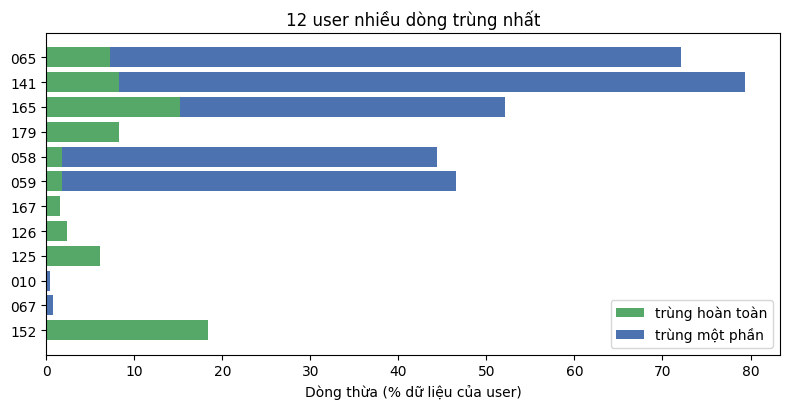

In [10]:
ut = PU[PU["n_extra"] > 0].copy()
ut["dòng thừa % (của user)"] = ut["n_extra"] / ut["n_rows"] * 100
ut["trùng hoàn toàn %"] = EX.groupby("user")["identical"].mean() * 100
ut["cỡ nhóm"] = EX.groupby("user")["group_size"].median().astype(int)
ut = ut.sort_values("n_extra", ascending=False)
ut["% tổng dòng thừa (cộng dồn)"] = ut["n_extra"].cumsum() / n_extra * 100
display(ut.head(8)[["n_extra", "dòng thừa % (của user)", "trùng hoàn toàn %", "cỡ nhóm", "% tổng dòng thừa (cộng dồn)"]]
        .rename(columns={"n_extra": "dòng thừa"}).round(1))

top = ut.head(12).iloc[::-1]
full = top["dòng thừa % (của user)"] * top["trùng hoàn toàn %"] / 100
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(top.index, full, color="#55a868", label="trùng hoàn toàn")
ax.barh(top.index, top["dòng thừa % (của user)"] - full, left=full, color="#4c72b0", label="trùng một phần")
ax.set_xlabel("Dòng thừa (% dữ liệu của user)")
ax.set_title("12 user nhiều dòng trùng nhất")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Đọc kết quả:** dòng thừa chiếm 2,81% dữ liệu nhưng rất tập trung: 3 user 065, 141, 165 chiếm khoảng 89%, và ở 3 user này hơn một nửa dữ liệu là dòng thừa.

### 3.2 Dòng trùng giống nhau ở cột nào

Date và time luôn giống nhau trong nhóm (chúng tạo ra timestamp), nên so 5 trường còn lại bằng chữ gốc. `khớp %` là tỷ lệ dòng thừa có trường đó giống hệt dòng đầu nhóm.

,khớp %,số dòng khác
lat,35.32,452062
lon,28.61,498949
độ cao,99.78,1559
cột 0,100.00,0
cột ngày,100.00,0
lat và lon,17.53,576417
mọi cột (trùng hoàn toàn),17.52,576431


Dòng thừa cùng file với dòng đầu nhóm: 100%  |  nằm ngay sau dòng trước trong file: 100%


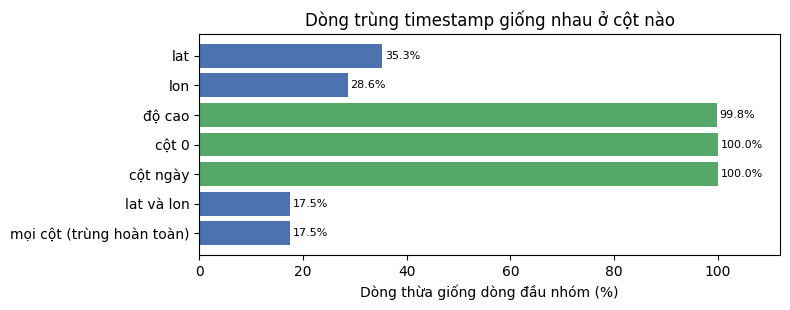

In [11]:
fields = {f"eq_{c}": n for c, n in dups.MATCH_FIELDS.items()}
col = EX[list(fields)].rename(columns=fields)
col["lat và lon"] = EX["eq_lat"] & EX["eq_lon"]
col["mọi cột (trùng hoàn toàn)"] = EX["identical"]
col_tab = pd.DataFrame({"khớp %": col.mean() * 100, "số dòng khác": (~col).sum()})
display(col_tab.round(2))
print(f"Dòng thừa cùng file với dòng đầu nhóm: {EX['same_file'].mean() * 100:.0f}%  |  "
      f"nằm ngay sau dòng trước trong file: {EX['adjacent'].mean() * 100:.0f}%")

fig, ax = plt.subplots(figsize=(8, 3.2))
v = col_tab["khớp %"].iloc[::-1]
bars = ax.barh(v.index, v, color=["#55a868" if x > 99 else "#4c72b0" for x in v])
ax.bar_label(bars, fmt="%.1f%%", fontsize=8, padding=2)
ax.set_xlim(0, 112)
ax.set_xlabel("Dòng thừa giống dòng đầu nhóm (%)")
ax.set_title("Dòng trùng timestamp giống nhau ở cột nào")
plt.tight_layout()
plt.show()

In [12]:
# Trùng hoàn toàn hay một phần: tổ hợp các cột khác dòng đầu nhóm
EX["tổ hợp"] = dups.diff_pattern(EX)
pt = EX.groupby("tổ hợp").agg(dòng_thừa=("user", "size"), khoảng_cách_trung_vị_m=("d_first_m", "median"))
pt.insert(1, "% dòng thừa", pt["dòng_thừa"] / n_extra * 100)
pt.sort_values("dòng_thừa", ascending=False).round(2)

,dòng_thừa,% dòng thừa,khoảng_cách_trung_vị_m
tổ hợp,,,
khác: lat + lon,373152,53.39,0.93
khác: lon,124297,17.78,0.28
giống hệt,122469,17.52,0.00
khác: lat,77423,11.08,0.19
khác: lat + lon + độ cao,1442,0.21,9.45
khác: lon + độ cao,58,0.01,4.44
khác: lat + độ cao,45,0.01,3.89
khác: độ cao,14,0.00,0.00


**Đọc kết quả:**
- Cột 0 và cột ngày luôn giống nhau, độ cao giống ở 99,8%. Phần khác nhau gần như chỉ là **lat, lon**.
- **Trùng hoàn toàn** (giống mọi cột) chiếm 17,5% dòng thừa
- **Chỉ khác độ cao** có 14 dòng
- Còn lại (82%) là **khác lat / lon**, nhưng khoảng cách trung vị dưới 1 m. Lệch bao xa: xem tuning/05.
- Mọi dòng thừa nằm cùng file và ngay sau nhau: trùng sinh ra lúc ghi, không phải do hai file chồng nhau.

### 3.3 Hai kiểu trùng

Cỡ nhóm k là số dòng cùng một timestamp (cho k − 1 dòng thừa).

In [13]:
gs = EX.groupby("group_size").agg(dòng_thừa=("user", "size"), trùng_hoàn_toàn_pct=("identical", "mean"))
gs["trùng_hoàn_toàn_pct"] *= 100
gs.insert(1, "% dòng thừa", gs["dòng_thừa"] / n_extra * 100)
gs["user chính"] = EX.groupby("group_size")["user"].agg(lambda s: ", ".join(s.value_counts().index[:4]))
gs.index.name = "cỡ nhóm"
gs.sort_values("dòng_thừa", ascending=False).head(4).round(1)

,dòng_thừa,% dòng thừa,trùng_hoàn_toàn_pct,user chính
cỡ nhóm,,,,
5,642136,91.9,11.9,"065, 141, 165, 059"
2,48838,7.0,90.5,"179, 167, 126, 125"
4,5376,0.8,10.1,"065, 141, 165, 059"
3,2470,0.4,39.4,"152, 141, 065, 165"


**Đọc kết quả:**
- **Cỡ nhóm 5 (92% dòng thừa; 065, 141, 165...):** thiết bị ghi 5 lần mỗi giây nhưng timestamp chỉ tới giây, nên 5 dòng chung một timestamp và lệch nhau chút ít.
- **Cỡ nhóm 2 (179, 167, 126...):** gần như luôn trùng hoàn toàn, tức thiết bị ghi lặp nguyên dòng.

### 3.4 File trùng giữa các user

Bỏ trùng theo timestamp chỉ làm trong từng user, nên không thấy một file bị chép sang user khác. Ở đây so các file **cùng tên** ở nhiều user bằng md5 (giống từng byte). Đây là cận dưới, vì file giống hệt nhưng khác tên không bị phát hiện.

In [14]:
CU = dups.cross_user_groups(progress=False)
cut_tabs = dups.cross_user_tables(CU, PU["n_rows"])
tt = cut_tabs["totals"]
display(pd.Series({"số user có file trùng với user khác": int(tt["số user liên quan"]),
                   "bản sao thừa (file)": int(tt["bản sao thừa (file)"]),
                   "dòng thừa do sao chép": int(tt["dòng thừa do nhân bản"]),
                   "% tổng dòng thô": round(tt["dòng thừa % tổng"], 2)}).to_frame("giá trị"))
print("Cặp user chung nhiều dữ liệu nhất")
display(cut_tabs["pairs"].head(6))
pu_cu = cut_tabs["per_user"]
print("User gần như toàn bộ dữ liệu là bản sao (≥ 90%)")
pu_cu[pu_cu["% dữ liệu của user"] >= 90][["số dòng trong các file đó", "% dữ liệu của user"]].round(1)

,giá trị
số user có file trùng với user khác,52.00
bản sao thừa (file),856.00
dòng thừa do sao chép,1495115.00
% tổng dòng thô,6.01


Cặp user chung nhiều dữ liệu nhất


,số file chung,số dòng chung
153 - 163,225,612042
126 - 167,145,209428
000 - 003,129,160928
010 - 124,10,120113
128 - 153,54,38993
055 - 075,12,37468


User gần như toàn bộ dữ liệu là bản sao (≥ 90%)


,số dòng trong các file đó,% dữ liệu của user
000,160928,92.6
124,120113,100.0
075,37468,99.8
055,37468,99.2
070,35311,100.0
088,27030,100.0
059,23606,100.0
058,23606,95.3
127,22853,100.0
156,16277,100.0


**Đọc kết quả:** khoảng 6% dữ liệu là file chép y hệt sang user khác, nhiều hơn cả dòng trùng timestamp. Vì pipeline xử lý theo từng user nên không xoá ở bước làm sạch, mà dùng để chia validation/test theo cụm user (`dups.user_components`, D17). Có loại các user gần như toàn là bản sao hay không: chưa quyết định.